In [7]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import re
from sklearn.metrics import mean_squared_error

In [8]:
from matplotlib.font_manager import FontProperties
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 16
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False

In [9]:
from matplotlib.colors import to_rgba
from itertools import cycle

### Function to extract defect types 

In [10]:
def extract_defect_type(filename):
    if 'te_' in filename and 'bi_' in filename:
        return r'A$_{Te@Bi}$'
    elif 'bi_' in filename and 'te1' in filename:
        return r'A$_{Bi@Te1}$'
    elif 'bi_' in filename and 'te2' in filename:
        return r'A$_{Bi@Te2}$'
    elif 'te1' in filename and 'bi' not in filename and 'te2' not in filename:
        return r'V$_{Te1}$'
    elif 'te2' in filename and 'bi' not in filename and 'te1' not in filename:
        return r'V$_{Te2}$'
    elif 'bi' in filename and 'te1' not in filename and 'te2' not in filename:
        return r'V$_{Bi}$'
    return 'Unknown'

In [11]:
data = pd.read_csv('dat_104_samples.csv')

In [12]:
data.fillna(0, inplace=True)

In [13]:
data = data.loc[:, (data != 0).any(axis=0)]

In [14]:
structures = list(data.structures)

In [15]:
data

,v_2.50,v_2.55,v_2.60,v_2.65,v_2.70,v_2.75,v_2.80,v_2.85,v_2.90,v_2.95,...,v_9.70,v_9.75,v_9.80,v_9.85,v_9.90,v_9.95,structures,structure_filenames,Defect_Type,carrier_type
0,0.000000,0.000000,0.000000,0.000000,0.000279,0.001079,0.026155,0.166841,0.786174,2.258237,...,1.205719,1.454713,1.858435,2.192166,2.210589,2.049151,2,bi1_0.95_occupancy_i00_w16.cif,V$_{Bi} - 5 \%$,p
1,0.000000,0.000000,0.000000,0.000000,0.000281,0.001493,0.025497,0.172104,0.849195,2.443885,...,1.207787,1.594998,2.063954,2.335641,2.186162,1.836268,3,te1_0.95_occupancy_i00_w16.cif,V$_{Te1} - 5 \%$,i
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.001491,0.021446,0.167892,0.834671,2.563078,...,1.159627,1.532494,2.060876,2.362143,2.180702,1.804726,4,te2_0.85_occupancy_i0_w8.cif,V$_{Te2} - 15 \%$,p
3,0.000000,0.000000,0.000000,0.001381,0.003859,0.024516,0.088448,0.292218,0.798247,1.926382,...,1.039586,1.277848,1.610805,1.796155,1.742256,1.529058,5,te_0.05_bi_0.95_occupancy_i00_w16.cif,A$_{Te@Bi} - 5 \%$,n
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.001042,0.013259,0.137642,0.692564,2.217128,...,1.264581,1.572307,2.019095,2.309045,2.089141,1.747118,6,bi_0.1_te2_0.9_occupancy_i0_w8.cif,A$_{Bi@Te2} - 10 \%$,p
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,0.001092,0.006309,0.036461,0.110833,0.186791,0.300472,0.440596,0.573335,1.088325,2.298142,...,1.419584,1.593107,2.002077,2.210743,2.185702,1.941102,112,te_0.2_bi_0.8_occupancy_i005_w16.cif,A$_{Te@Bi} - 20 \%$,n
100,0.000000,0.000000,0.000000,0.000000,0.000000,0.001543,0.015522,0.136226,0.653774,2.004292,...,1.524655,1.570864,1.769099,1.886416,1.862321,1.849636,114,bi_0.2_te1_0.8_occupancy_i005_w16.cif,A$_{Bi@Te1} - 20 \%$,p
101,0.000000,0.000000,0.000000,0.000000,0.000801,0.008249,0.052796,0.221473,0.778280,1.976610,...,1.058691,1.290718,1.573368,1.715519,1.674754,1.552991,116,bi_0.2_te1_0.8_occupancy_i000_w48.cif,A$_{Bi@Te1} - 20 \%$,p
102,0.000000,0.000000,0.000000,0.000000,0.010371,0.068275,0.240868,0.690578,1.470730,2.834029,...,1.433747,1.706986,2.088140,2.367960,2.275389,2.031910,117,te_0.2_bi_0.8_occupancy_i000_w48.cif,A$_{Te@Bi} - 20 \%$,n


In [16]:
df = data.drop(columns=['structure_filenames', 'structures', 'Defect_Type', 'carrier_type'])

In [17]:
df

,v_2.50,v_2.55,v_2.60,v_2.65,v_2.70,v_2.75,v_2.80,v_2.85,v_2.90,v_2.95,...,v_9.50,v_9.55,v_9.60,v_9.65,v_9.70,v_9.75,v_9.80,v_9.85,v_9.90,v_9.95
0,0.000000,0.000000,0.000000,0.000000,0.000279,0.001079,0.026155,0.166841,0.786174,2.258237,...,1.629593,1.674368,1.475219,1.260361,1.205719,1.454713,1.858435,2.192166,2.210589,2.049151
1,0.000000,0.000000,0.000000,0.000000,0.000281,0.001493,0.025497,0.172104,0.849195,2.443885,...,2.057786,1.703706,1.215795,1.038992,1.207787,1.594998,2.063954,2.335641,2.186162,1.836268
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.001491,0.021446,0.167892,0.834671,2.563078,...,2.041142,1.709108,1.256446,1.035247,1.159627,1.532494,2.060876,2.362143,2.180702,1.804726
3,0.000000,0.000000,0.000000,0.001381,0.003859,0.024516,0.088448,0.292218,0.798247,1.926382,...,1.603079,1.390790,1.044763,0.927457,1.039586,1.277848,1.610805,1.796155,1.742256,1.529058
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.001042,0.013259,0.137642,0.692564,2.217128,...,2.078597,1.768529,1.297915,1.141044,1.264581,1.572307,2.019095,2.309045,2.089141,1.747118
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,0.001092,0.006309,0.036461,0.110833,0.186791,0.300472,0.440596,0.573335,1.088325,2.298142,...,1.818168,1.864899,1.632384,1.421349,1.419584,1.593107,2.002077,2.210743,2.185702,1.941102
100,0.000000,0.000000,0.000000,0.000000,0.000000,0.001543,0.015522,0.136226,0.653774,2.004292,...,1.541795,1.628053,1.718823,1.650243,1.524655,1.570864,1.769099,1.886416,1.862321,1.849636
101,0.000000,0.000000,0.000000,0.000000,0.000801,0.008249,0.052796,0.221473,0.778280,1.976610,...,1.499658,1.322607,1.105821,0.996672,1.058691,1.290718,1.573368,1.715519,1.674754,1.552991
102,0.000000,0.000000,0.000000,0.000000,0.010371,0.068275,0.240868,0.690578,1.470730,2.834029,...,1.981502,1.784766,1.511174,1.395877,1.433747,1.706986,2.088140,2.367960,2.275389,2.031910


In [12]:
### Data Processing

In [18]:
gr_columns = [col for col in df.columns if re.match(r'v_\d+\.\d+', col)]
radii_values = [float(col.split('_')[1]) for col in gr_columns]

In [19]:
gr_data = df[gr_columns]

### Define unique defects

In [20]:
unique_defects = data['Defect_Type'].unique()

In [21]:
markers = cycle(['o', 'd', 'v', '^', 's', '*', 'h', 'X', 'D','p'])
colors = plt.cm.tab20b(range(len(unique_defects))) 
marker_color_map = {defect: (next(markers), to_rgba(colors[i])) for i, defect in enumerate(unique_defects)}

### Define carrier types

In [22]:
c_types = data['carrier_type'].unique()

markers_c = cycle(['o', '^', 's'])
colors_c = plt.cm.tab10(range(len(c_types))) 
marker_color_map_c = {c_type: (next(markers_c), to_rgba(colors_c[i])) for i, c_type in enumerate(c_types)}

### compute PCs 

In [23]:
scaler = MinMaxScaler()
gr_data_scaled = scaler.fit_transform(gr_data) 

#pca = PCA(n_components=6)
#pca_results = pca.fit_transform(gr_data_scaled)

In [24]:
gr_data

,v_2.50,v_2.55,v_2.60,v_2.65,v_2.70,v_2.75,v_2.80,v_2.85,v_2.90,v_2.95,...,v_9.50,v_9.55,v_9.60,v_9.65,v_9.70,v_9.75,v_9.80,v_9.85,v_9.90,v_9.95
0,0.000000,0.000000,0.000000,0.000000,0.000279,0.001079,0.026155,0.166841,0.786174,2.258237,...,1.629593,1.674368,1.475219,1.260361,1.205719,1.454713,1.858435,2.192166,2.210589,2.049151
1,0.000000,0.000000,0.000000,0.000000,0.000281,0.001493,0.025497,0.172104,0.849195,2.443885,...,2.057786,1.703706,1.215795,1.038992,1.207787,1.594998,2.063954,2.335641,2.186162,1.836268
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.001491,0.021446,0.167892,0.834671,2.563078,...,2.041142,1.709108,1.256446,1.035247,1.159627,1.532494,2.060876,2.362143,2.180702,1.804726
3,0.000000,0.000000,0.000000,0.001381,0.003859,0.024516,0.088448,0.292218,0.798247,1.926382,...,1.603079,1.390790,1.044763,0.927457,1.039586,1.277848,1.610805,1.796155,1.742256,1.529058
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.001042,0.013259,0.137642,0.692564,2.217128,...,2.078597,1.768529,1.297915,1.141044,1.264581,1.572307,2.019095,2.309045,2.089141,1.747118
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,0.001092,0.006309,0.036461,0.110833,0.186791,0.300472,0.440596,0.573335,1.088325,2.298142,...,1.818168,1.864899,1.632384,1.421349,1.419584,1.593107,2.002077,2.210743,2.185702,1.941102
100,0.000000,0.000000,0.000000,0.000000,0.000000,0.001543,0.015522,0.136226,0.653774,2.004292,...,1.541795,1.628053,1.718823,1.650243,1.524655,1.570864,1.769099,1.886416,1.862321,1.849636
101,0.000000,0.000000,0.000000,0.000000,0.000801,0.008249,0.052796,0.221473,0.778280,1.976610,...,1.499658,1.322607,1.105821,0.996672,1.058691,1.290718,1.573368,1.715519,1.674754,1.552991
102,0.000000,0.000000,0.000000,0.000000,0.010371,0.068275,0.240868,0.690578,1.470730,2.834029,...,1.981502,1.784766,1.511174,1.395877,1.433747,1.706986,2.088140,2.367960,2.275389,2.031910


### For n_PC = 6

In [ ]:
# output directory
output_dir = "/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/"
os.makedirs(output_dir, exist_ok=True)

# extract loadings and explained variance
loadings = pca.components_.T
explained_variance_ratios = pca.explained_variance_ratio_

# Define ranges for visualization
ranges = [(0, 4), (4, 7), (7, 10)]

#score plots for all pairwise combinations of PCs 1 to 10 w.r.t defect type
for pc_x in range(6):
    for pc_y in range(pc_x + 1, 6):
        plt.figure(figsize=(8, 6))
        for defect in unique_defects:
            indices = data['Defect_Type'] == defect
            marker, color = marker_color_map[defect]
            plt.scatter(
                pca_results[indices, pc_x],
                pca_results[indices, pc_y],
                label=defect,
                marker=marker,
                color=color,
                edgecolors='black',
                alpha=0.7,
                s=100
            )
        plt.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
        plt.axvline(x=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)    
        plt.xlabel(f"PC{pc_x + 1} ({pca.explained_variance_ratio_[pc_x] * 100:.2f}% variance)")
        plt.ylabel(f"PC{pc_y + 1} ({pca.explained_variance_ratio_[pc_y] * 100:.2f}% variance)")
        plt.legend(
            title="Defect Types", fontsize=9, title_fontsize=10,
            loc='upper right', bbox_to_anchor=(1.3, 1), borderaxespad=0
        )
        plt.tight_layout()
        filename = f"{output_dir}/Score_PC{pc_x + 1}_vs_PC{pc_y + 1}_def_type.png"
        plt.savefig(filename, dpi=600, bbox_inches="tight")
        plt.show()
        
#score plots for all pairwise combinations of PCs 1 to 10 w.r.t carrier type
for pc_x in range(10):
    for pc_y in range(pc_x + 1, 6):
        plt.figure(figsize=(6,4))
        for c_type in c_types:
            indices = data['carrier_type'] == c_type
            marker, color = marker_color_map_c[c_type]
            plt.scatter(
                pca_results[indices, pc_x],
                pca_results[indices, pc_y],
                label=c_type,
                marker=marker,
                color=color,
                edgecolors='black',
                alpha=0.7,
                s=100
            )
        plt.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
        plt.axvline(x=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)    
        plt.xlabel(f"PC{pc_x + 1} ({pca.explained_variance_ratio_[pc_x] * 100:.2f}% variance)")
        plt.ylabel(f"PC{pc_y + 1} ({pca.explained_variance_ratio_[pc_y] * 100:.2f}% variance)")
        plt.legend(
            #title="Carrier Types", fontsize=9, title_fontsize=16,
            loc='upper right', bbox_to_anchor=(1.2, 1), borderaxespad=0
        )
        plt.tight_layout()
        filename = f"{output_dir}/Score_PC{pc_x + 1}_vs_PC{pc_y + 1}_c_type.png"
        plt.savefig(filename, dpi=600, bbox_inches="tight")
        plt.show()

# plot PCA Loadings
for pc_idx in range(6):  
    explained_variance = explained_variance_ratios[pc_idx] * 100
    for range_idx, (low, high) in enumerate(ranges):
        indices = [i for i, r in enumerate(radii_values) if low <= r < high and loadings[i, pc_idx] != 0]
        if indices:
            selected_radii = [radii_values[idx] for idx in indices]
            selected_loadings = loadings[indices, pc_idx]
            
            plt.figure(figsize=(20, 6))
            plt.bar(selected_radii, selected_loadings, width=0.03, alpha=0.7, label=f'PC{pc_idx + 1}')
            plt.xlabel("Radii (Å)")
            plt.ylabel(f"PC{pc_idx + 1} Loadings ({explained_variance:.2f}% variance)")
            plt.xticks(ticks=np.arange(min(selected_radii), max(selected_radii) + 0.5, 0.5), rotation=90)
            plt.ylim(-0.3,0.3)
           # plt.legend()
            filename = f"{output_dir}/PC{pc_idx + 1}_Range_{low}-{high}_v2.png"
            plt.savefig(filename, dpi=600, bbox_inches="tight")
            plt.show()

pca_loading_df = pd.DataFrame(
    loadings,  # shape: [num_features, num_components]
    columns=[f"PC{i+1}" for i in range(loadings.shape[1])]
)

# Add radius values to the front of the DataFrame
pca_loading_df.insert(0, "Radius (Å)", radii_values)

# Save loadings datato CSV
csv_path = os.path.join(output_dir, "PCA_Loadings_by_Radius.csv")
pca_loading_df.to_csv(csv_path, index=False)


#Compute PCA Reconstruction Error for Different Components
reconstruction_errors_PCA = []
for n_components in range(6): 
    pca = PCA(n_components=n_components)
    transformed_data = pca.fit_transform(gr_data_scaled)
    reconstructed_data = pca.inverse_transform(transformed_data)
    
    # Compute Mean Squared Error (MSE) 
        # Scalar MSE across all samples & features
  #  mse = float(((gr_data - reconstructed_data) ** 2).mean())
    mse = np.mean((gr_data_scaled - reconstructed_data) ** 2)
    reconstruction_errors_PCA.append((n_components, mse))


reconstruction_errors_PCA_fin = np.array(reconstruction_errors_PCA)


#plt.figure(figsize=(6, 4))
#plt.plot(reconstruction_errors_PCA_fin[:, 0], reconstruction_errors_PCA_fin[:, 1], marker="o", linestyle="-", color="k")
#plt.xlabel("Number of Components")
#plt.ylabel("Reconstruction Error (MSE)")
#plt.savefig(f"{output_dir}/Reconstruction_Error_vs_Components_PCA_v2.png", dpi=300, bbox_inches="tight")
#plt.show()

In [ ]:
# reconstruction errors

plt.figure(figsize=(6, 4))
plt.plot(reconstruction_errors_PCA_fin[:, 0]+1, reconstruction_errors_PCA_fin[:, 1], marker="o", linestyle="-", color="k")
plt.xlabel("Number of Components")
plt.ylabel("Reconstruction Error (MSE)")
plt.savefig(f"{output_dir}/Reconstruction_Error_vs_Components_PCA.png", dpi=600, bbox_inches="tight")
plt.show()

In [ ]:
print(reconstruction_errors_PCA_fin)

In [ ]:
gr_data_scaled

In [ ]:
output_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/plots'
os.makedirs(output_dir, exist_ok=True)
# radial ranges
ranges = [(2.5, 4), (4, 7), (7, 10)]

# PC combinations
pc_combinations = [(1,2,3)]    

# Color map for PCs
pc_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink']

# Width of each bar
bar_width = 0.025

for combo in pc_combinations:
    for (low, high) in ranges:
        # Get indices of features in this range
        indices = [i for i, r in enumerate(radii_values) if low <= r < high]
        if not indices:
            continue

        selected_radii = [radii_values[i] for i in indices]

        plt.figure(figsize=(12, 4))
        for idx, pc_idx in enumerate(combo):
            pc_loadings = loadings[indices, pc_idx]
            plt.bar(
                selected_radii,
                pc_loadings,
                width=bar_width,
                alpha=0.5,
                color=pc_colors[pc_idx % len(pc_colors)],
                label=f'PC{pc_idx + 1}'
            )

        plt.xlabel("Radii (Å)")
        plt.ylabel("Loadings")
        #plt.title(f"{' vs '.join([f'PC{i+1}' for i in combo])} Loadings | Range: {low}-{high} Å")
        plt.xticks(ticks=np.arange(low, high + 0.5, 0.5), rotation=0)
        plt.ylim(-0.5, 0.5)
        plt.legend()
        plt.minorticks_on()
        plt.tick_params(which='both', direction='in', top=True, right=True, left=True, bottom = True)
        plt.tick_params(which='major', length=6)
        plt.tick_params(which='minor', length=3)
        plt.grid(True, alpha=0.3) #axis='y',
        plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.8), borderaxespad=0.0)
        plt.tight_layout(rect=[0, 0, 0.82, 1])
        filename = f"{output_dir}/{'_vs_'.join([f'PC{i+1}' for i in combo])}_Range_{low}-{high}_hist.png"
        plt.savefig(filename, dpi=600, bbox_inches="tight")
        plt.show()

### save data

In [ ]:
# 1. save PCs 
output_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/'
pc_df = pd.DataFrame(pca_results, columns=[f'PC{i+1}' for i in range(6)])
pc_df['Defect_Type'] = data['Defect_Type']
pc_df['structures'] = structures
pc_df["carrier_type"] = data["carrier_type"]
pc_df.to_csv(f"{output_dir}/PCA_with_Defect_Types.csv", index=False)

In [ ]:
output_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/plots/class_types'
os.makedirs(output_dir, exist_ok=True)
# radial ranges
ranges = [(2.5, 4), (4, 7), (7, 10)]

# PC combinations
pc_combinations = [(1,2,3)]    

# Color map for PCs
pc_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink']

# Width of each bar
bar_width = 0.025

for combo in pc_combinations:
    for (low, high) in ranges:
        # Get indices of features in this range
        indices = [i for i, r in enumerate(radii_values) if low <= r < high]
        if not indices:
            continue

        selected_radii = [radii_values[i] for i in indices]

        plt.figure(figsize=(12, 4))
        for idx, pc_idx in enumerate(combo):
            pc_loadings = loadings[indices, pc_idx]
            plt.bar(
                selected_radii,
                pc_loadings,
                width=bar_width,
                alpha=0.5,
                color=pc_colors[pc_idx % len(pc_colors)],
                label=f'PC{pc_idx + 1}'
            )

        plt.xlabel("Radii (Å)")
        plt.ylabel("Loadings")
        #plt.title(f"{' vs '.join([f'PC{i+1}' for i in combo])} Loadings | Range: {low}-{high} Å")
        plt.xticks(ticks=np.arange(low, high + 0.5, 0.5), rotation=0)
        plt.ylim(-0.5, 0.5)
        plt.legend()
        plt.minorticks_on()
        plt.tick_params(which='both', direction='in', top=True, right=True, left=True, bottom = True)
        plt.tick_params(which='major', length=6)
        plt.tick_params(which='minor', length=3)
        plt.grid(True, alpha=0.3) #axis='y',
        plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.8), borderaxespad=0.0)
        plt.tight_layout(rect=[0, 0, 0.82, 1])
        filename = f"{output_dir}/{'_vs_'.join([f'PC{i+1}' for i in combo])}_Range_{low}-{high}_hist_p_type.png"
        plt.savefig(filename, dpi=600, bbox_inches="tight")
        plt.show()

In [ ]:
output_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/plots/class_types'
os.makedirs(output_dir, exist_ok=True)
# radial ranges
ranges = [(2.5, 4), (4, 7), (7, 10)]

# PC combinations
pc_combinations = [(1,3,5)]    

# Color map for PCs
pc_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink']

# Width of each bar
bar_width = 0.025

for combo in pc_combinations:
    for (low, high) in ranges:
        # Get indices of features in this range
        indices = [i for i, r in enumerate(radii_values) if low <= r < high]
        if not indices:
            continue

        selected_radii = [radii_values[i] for i in indices]

        plt.figure(figsize=(12, 4))
        for idx, pc_idx in enumerate(combo):
            pc_loadings = loadings[indices, pc_idx]
            plt.bar(
                selected_radii,
                pc_loadings,
                width=bar_width,
                alpha=0.5,
                color=pc_colors[pc_idx % len(pc_colors)],
                label=f'PC{pc_idx + 1}'
            )

        plt.xlabel("Radii (Å)")
        plt.ylabel("Loadings")
        #plt.title(f"{' vs '.join([f'PC{i+1}' for i in combo])} Loadings | Range: {low}-{high} Å")
        plt.xticks(ticks=np.arange(low, high + 0.5, 0.5), rotation=0)
        plt.ylim(-0.5, 0.5)
        plt.legend()
        plt.minorticks_on()
        plt.tick_params(which='both', direction='in', top=True, right=True, left=True, bottom = True)
        plt.tick_params(which='major', length=6)
        plt.tick_params(which='minor', length=3)
        plt.grid(True, alpha=0.3) #axis='y',
        plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.8), borderaxespad=0.0)
        plt.tight_layout(rect=[0, 0, 0.82, 1])
        filename = f"{output_dir}/{'_vs_'.join([f'PC{i+1}' for i in combo])}_Range_{low}-{high}_hist_i_type.png"
        plt.savefig(filename, dpi=600, bbox_inches="tight")
        plt.show()

### For n_PC = 3

In [25]:
pca = PCA(n_components=3)
pca_results = pca.fit_transform(gr_data_scaled)

In [26]:
pca

PCA(n_components=3)

In [28]:
from joblib import dump, load

In [29]:
dump(pca, "pca_3components.joblib")

['pca_3components.joblib']

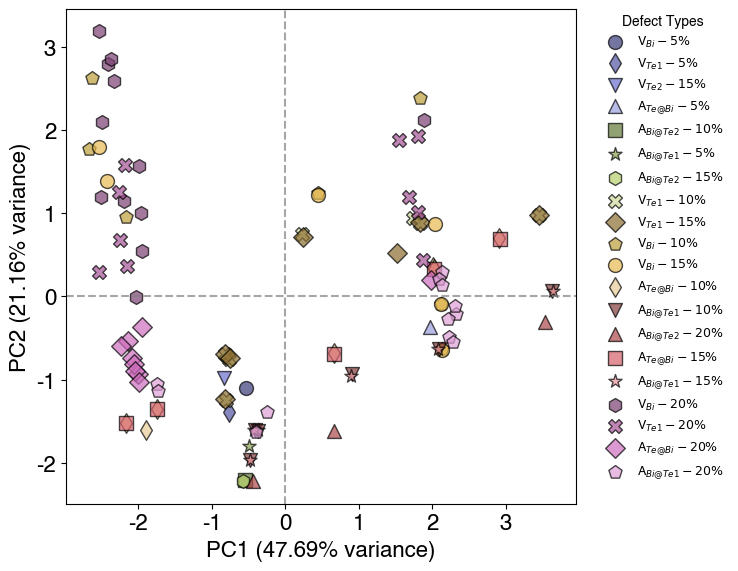

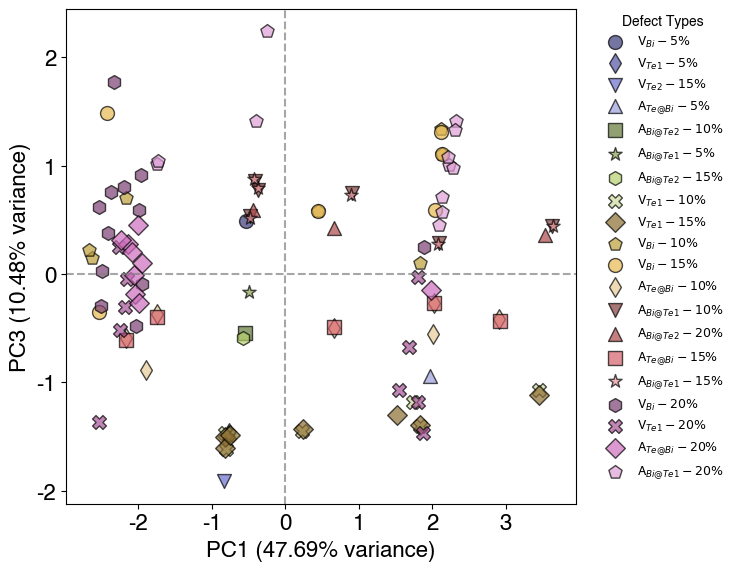

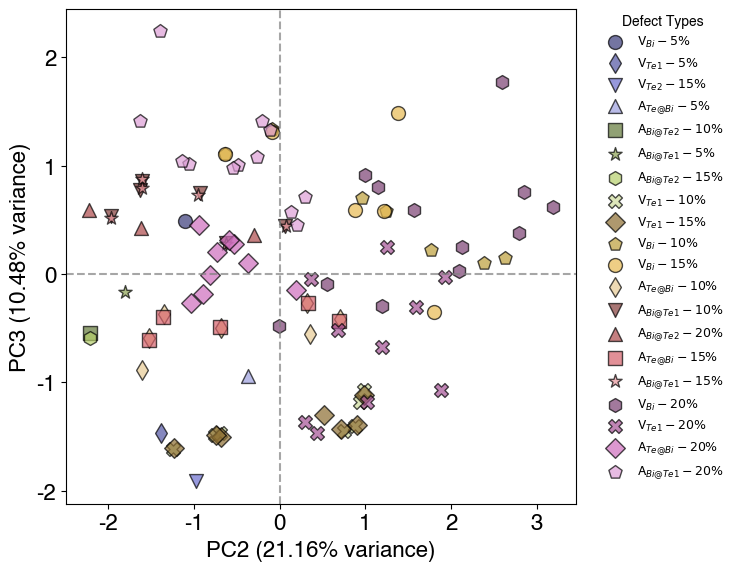

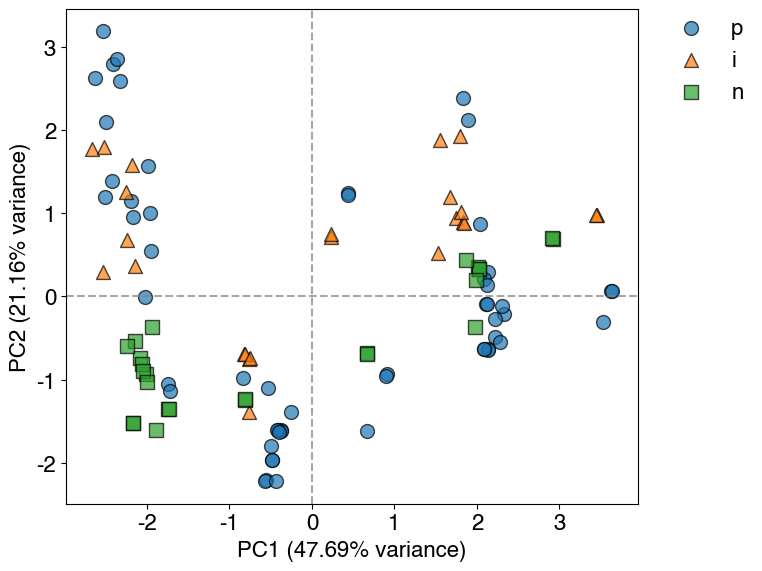

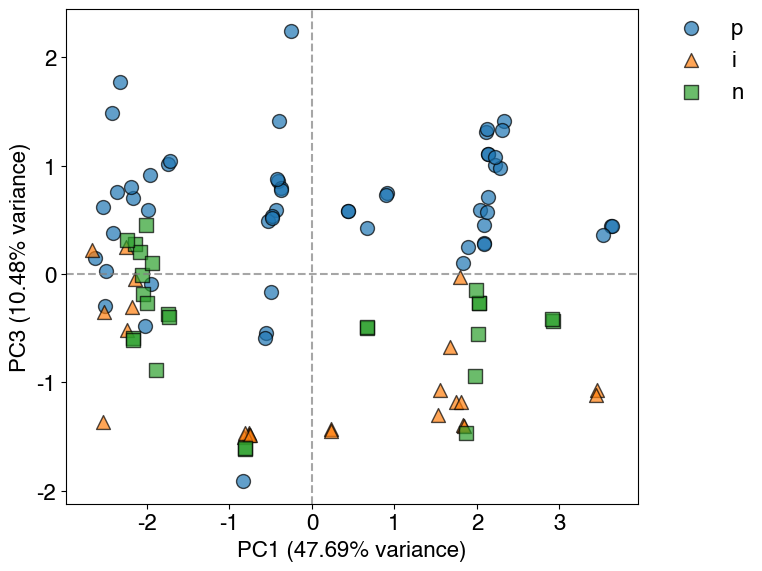

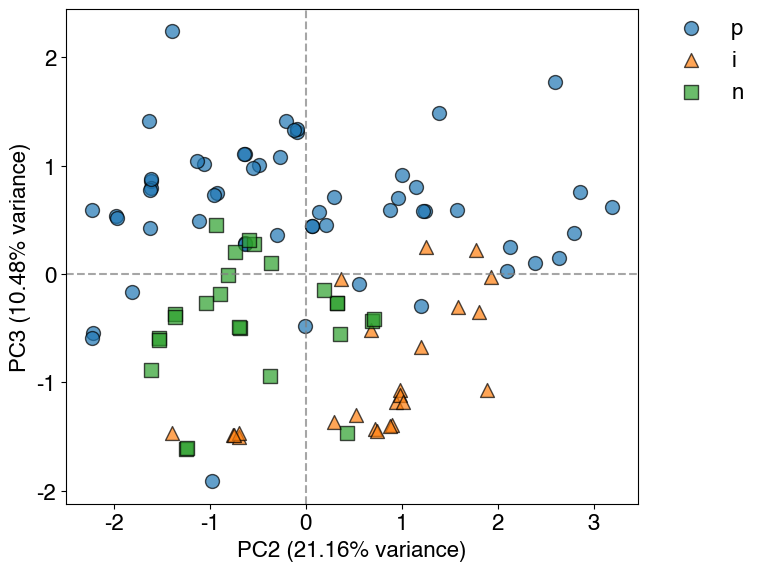

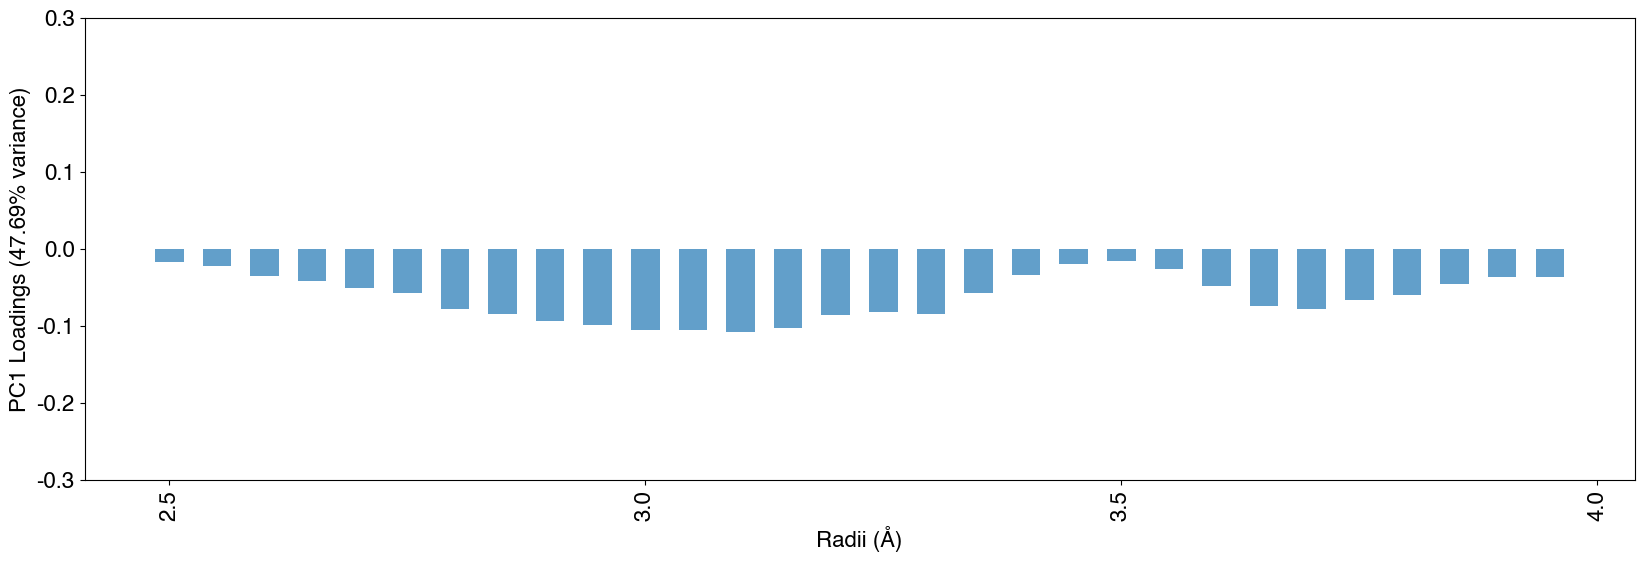

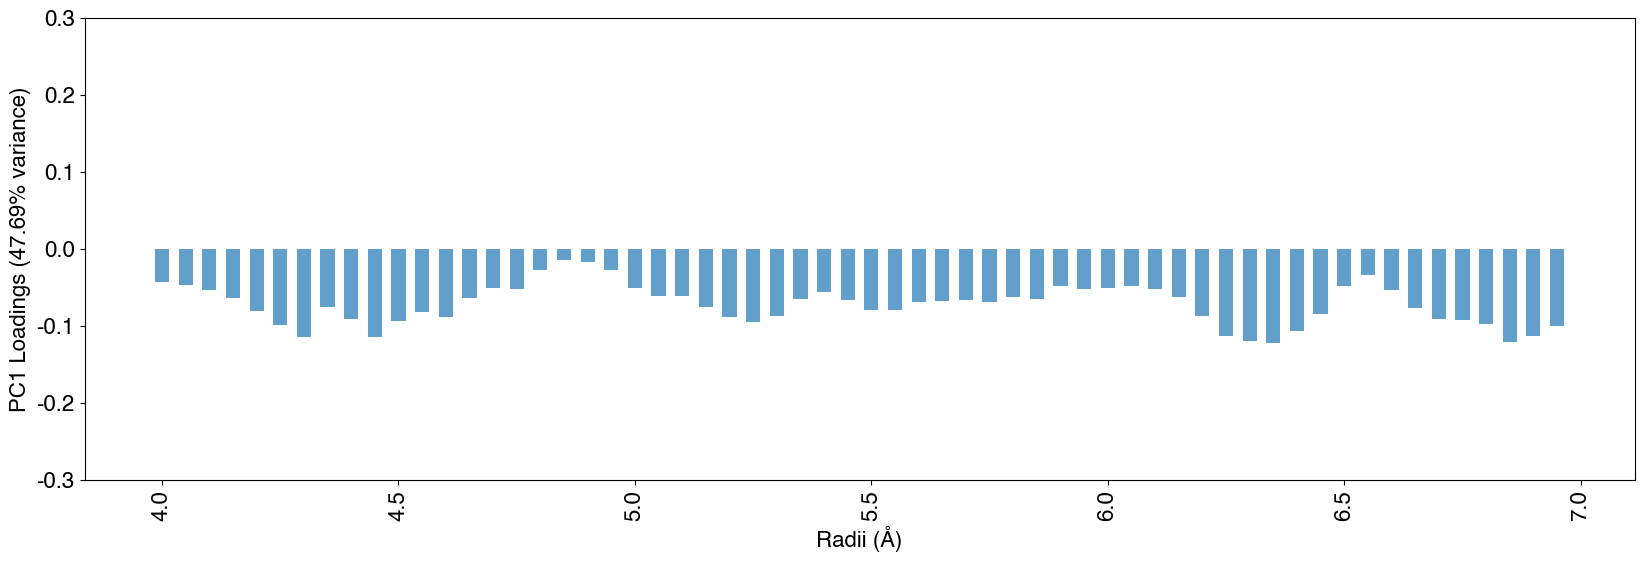

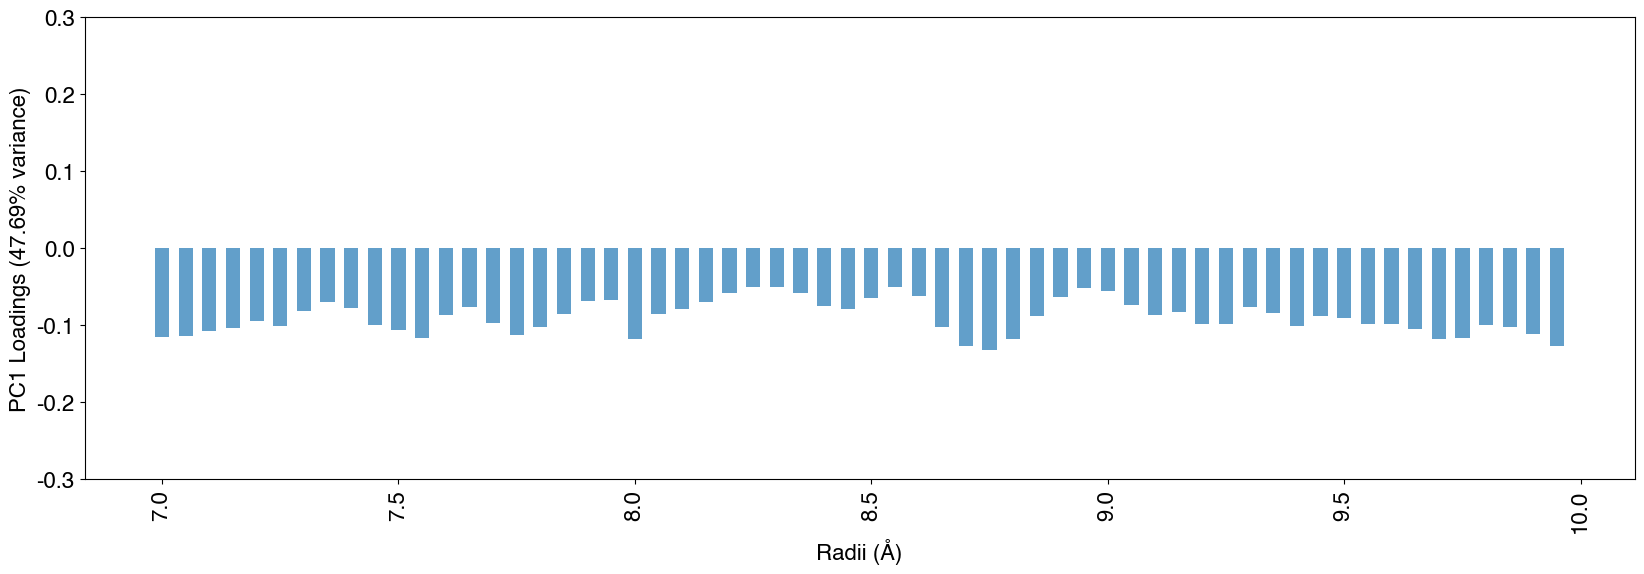

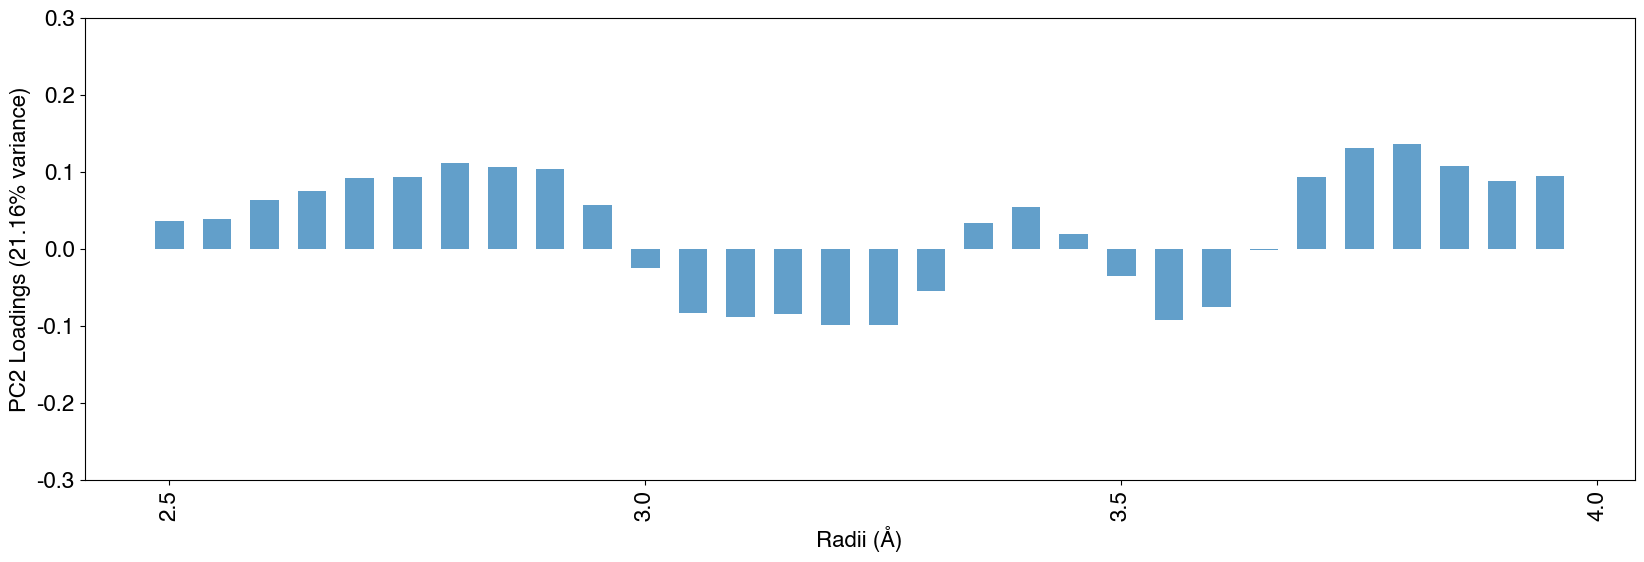

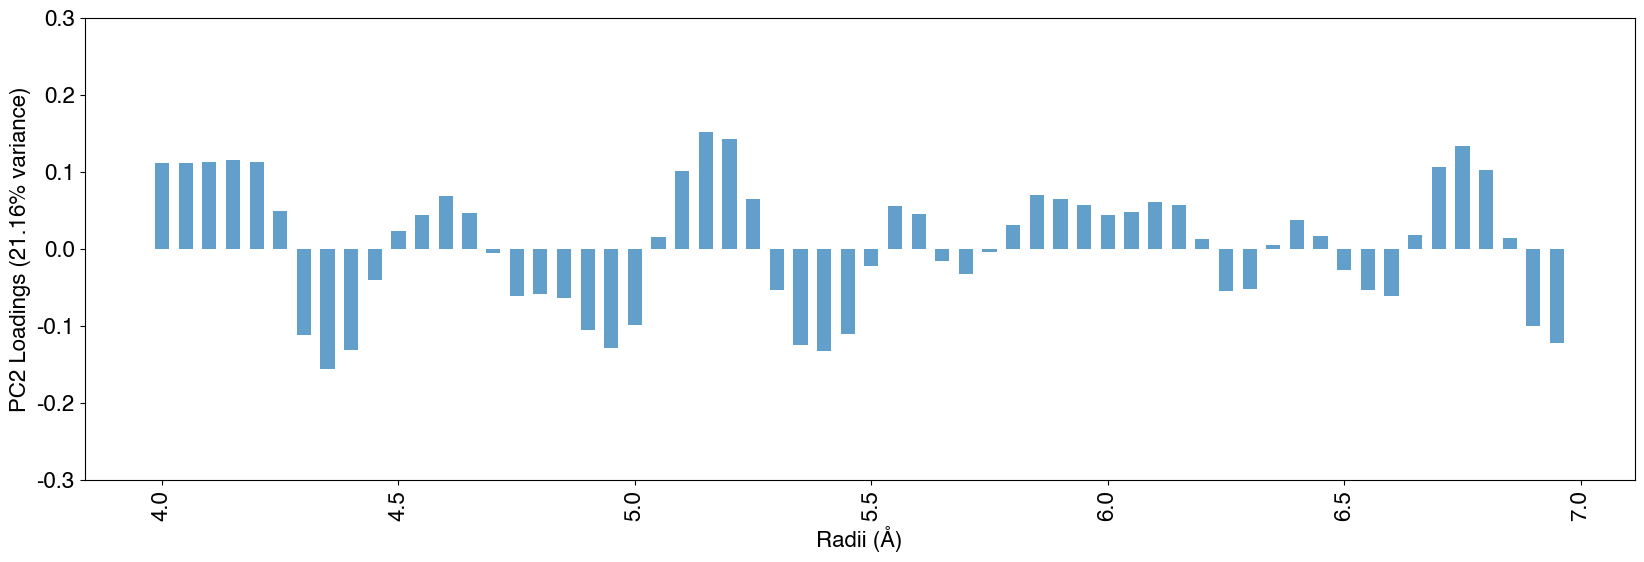

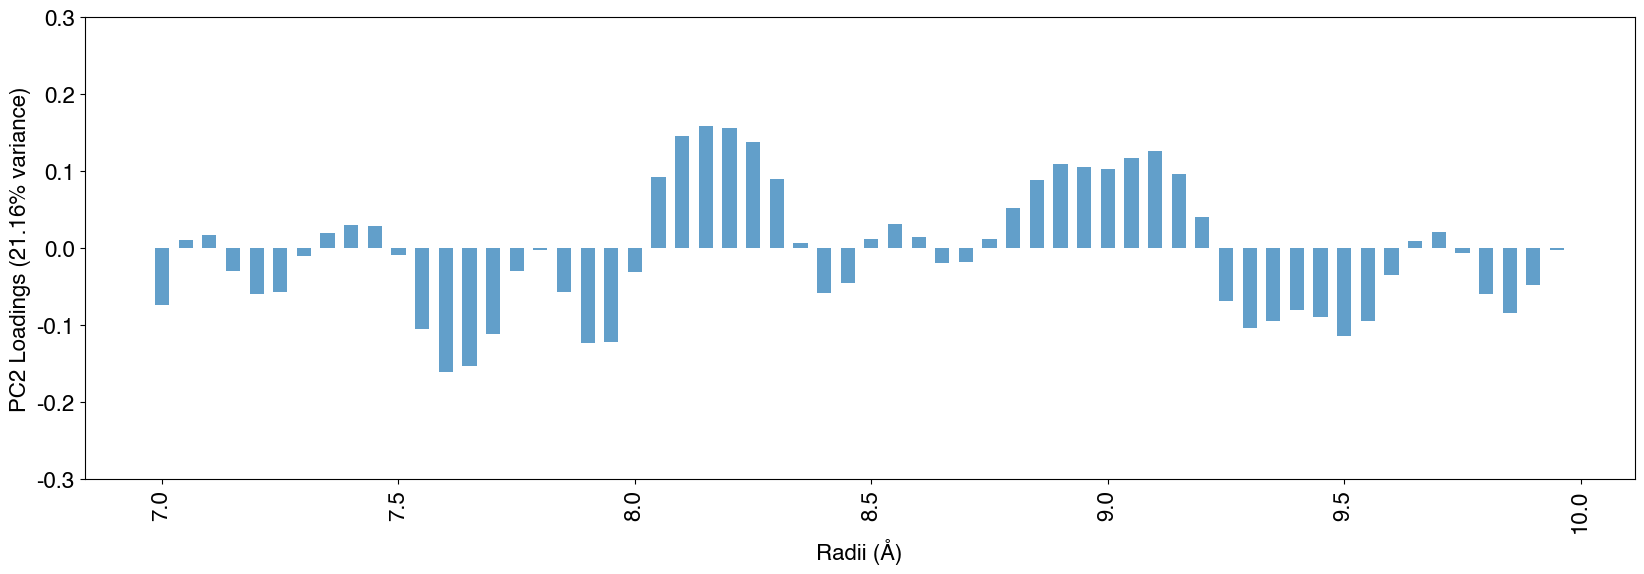

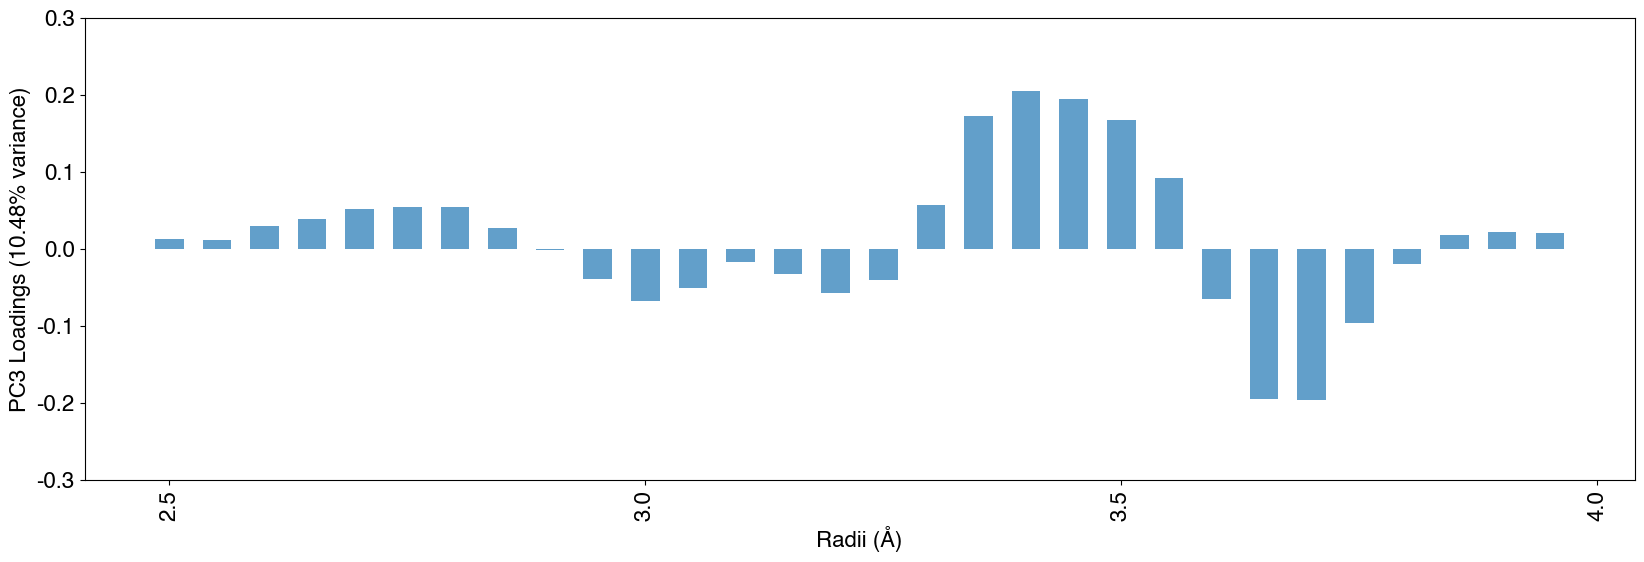

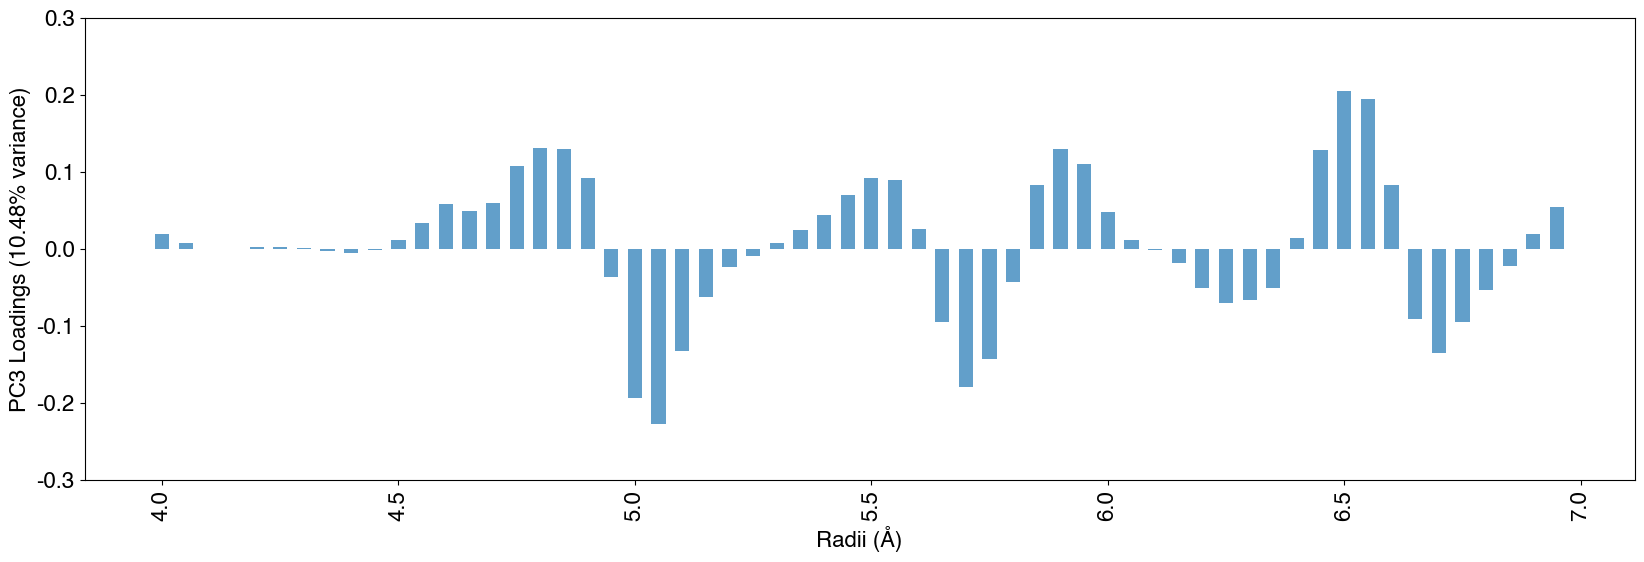

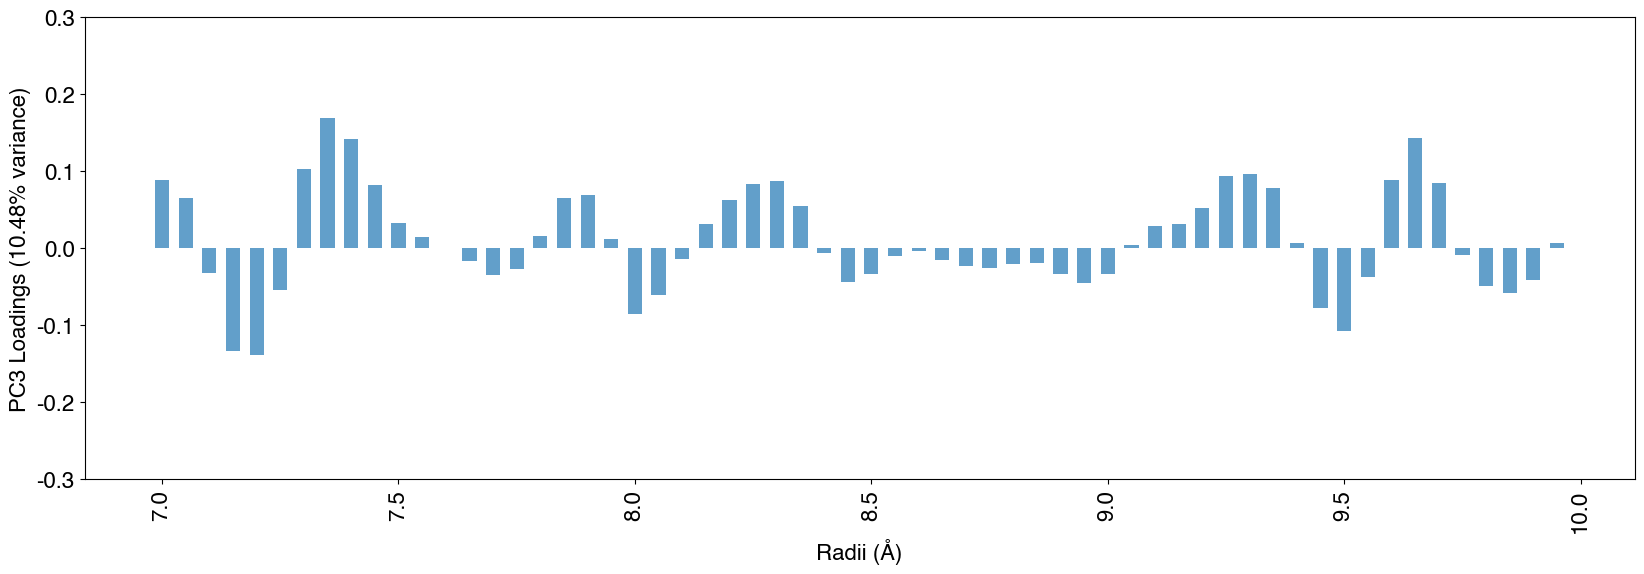

In [ ]:
# output directory
output_dir = "/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/n_PC3"
os.makedirs(output_dir, exist_ok=True)

#scaler = MinMaxScaler()
#gr_data_scaled = scaler.fit_transform(gr_data) 
pca = PCA(n_components=3)
pca_results = pca.fit_transform(gr_data_scaled)

# extract loadings and explained variance
loadings = pca.components_.T
explained_variance_ratios = pca.explained_variance_ratio_

# Define ranges for visualization
ranges = [(0, 4), (4, 7), (7, 10)]

#score plots for all pairwise combinations of PCs 1 to 3 w.r.t defect type
for pc_x in range(3):
    for pc_y in range(pc_x + 1, 3):
        plt.figure(figsize=(8, 6))
        for defect in unique_defects:
            indices = data['Defect_Type'] == defect
            marker, color = marker_color_map[defect]
            plt.scatter(
                pca_results[indices, pc_x],
                pca_results[indices, pc_y],
                label=defect,
                marker=marker,
                color=color,
                edgecolors='black',
                alpha=0.7,
                s=100
            )
        plt.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
        plt.axvline(x=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)    
        plt.xlabel(f"PC{pc_x + 1} ({pca.explained_variance_ratio_[pc_x] * 100:.1f}% variance)")
        plt.ylabel(f"PC{pc_y + 1} ({pca.explained_variance_ratio_[pc_y] * 100:.1f}% variance)")
        plt.legend(
            title="Defect Types", fontsize=9, title_fontsize=10,
            loc='upper right', bbox_to_anchor=(1.3, 1), borderaxespad=0
        )
        plt.tight_layout()
        filename = f"{output_dir}/Score_PC{pc_x + 1}_vs_PC{pc_y + 1}_def_type_nPC3.png"
        plt.savefig(filename, dpi=600, bbox_inches="tight")
        plt.show()
        
#score plots for all pairwise combinations of PCs 1 to 10 w.r.t carrier type
for pc_x in range(3):
    for pc_y in range(pc_x + 1, 3):
        plt.figure(figsize=(8,6))
        for c_type in c_types:
            indices = data['carrier_type'] == c_type
            marker, color = marker_color_map_c[c_type]
            plt.scatter(
                pca_results[indices, pc_x],
                pca_results[indices, pc_y],
                label=c_type,
                marker=marker,
                color=color,
                edgecolors='black',
                alpha=0.7,
                s=100
            )
        plt.axhline(y=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
        plt.axvline(x=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)    
        plt.xlabel(f"PC{pc_x + 1} ({pca.explained_variance_ratio_[pc_x] * 100:.2f}% variance)")
        plt.ylabel(f"PC{pc_y + 1} ({pca.explained_variance_ratio_[pc_y] * 100:.2f}% variance)")
        plt.legend(
            #title="Carrier Types", fontsize=9, title_fontsize=16,
            loc='upper right', bbox_to_anchor=(1.2, 1), borderaxespad=0
        )
        plt.tight_layout()
        filename = f"{output_dir}/Score_PC{pc_x + 1}_vs_PC{pc_y + 1}_c_type_nPC3.png"
        plt.savefig(filename, dpi=600, bbox_inches="tight")
        plt.show()

# plot PCA Loadings
for pc_idx in range(3):  
    explained_variance = explained_variance_ratios[pc_idx] * 100
    for range_idx, (low, high) in enumerate(ranges):
        indices = [i for i, r in enumerate(radii_values) if low <= r < high and loadings[i, pc_idx] != 0]
        if indices:
            selected_radii = [radii_values[idx] for idx in indices]
            selected_loadings = loadings[indices, pc_idx]
            
            plt.figure(figsize=(20, 6))
            plt.bar(selected_radii, selected_loadings, width=0.03, alpha=0.7, label=f'PC{pc_idx + 1}')
            plt.xlabel("Radii (Å)")
            plt.ylabel(f"PC{pc_idx + 1} Loadings ({explained_variance:.2f}% variance)")
            plt.xticks(ticks=np.arange(min(selected_radii), max(selected_radii) + 0.5, 0.5), rotation=90)
            plt.ylim(-0.3,0.3)
           # plt.legend()
            filename = f"{output_dir}/PC{pc_idx + 1}_Range_{low}-{high}_nPC3.png"
            plt.savefig(filename, dpi=600, bbox_inches="tight")
            plt.show()

pca_loading_df = pd.DataFrame(
    loadings,  # shape: [num_features, num_components]
    columns=[f"PC{i+1}" for i in range(loadings.shape[1])]
)

# Add radius values to the front of the DataFrame
pca_loading_df.insert(0, "Radius (Å)", radii_values)

# Save loadings datato CSV
csv_path = os.path.join(output_dir, "PCA_Loadings_by_Radius_nPC3.csv")
pca_loading_df.to_csv(csv_path, index=False)


#Compute PCA Reconstruction Error for Different Components
reconstruction_errors_PCA = []
for n_components in range(3): 
    pca = PCA(n_components=n_components)
    transformed_data = pca.fit_transform(gr_data_scaled)
    reconstructed_data = pca.inverse_transform(transformed_data)
    
    # Compute Mean Squared Error (MSE) 
        # Scalar MSE across all samples & features
  #  mse = float(((gr_data - reconstructed_data) ** 2).mean())
    mse = np.mean((gr_data_scaled - reconstructed_data) ** 2)
    reconstruction_errors_PCA.append((n_components, mse))


reconstruction_errors_PCA_fin = np.array(reconstruction_errors_PCA)

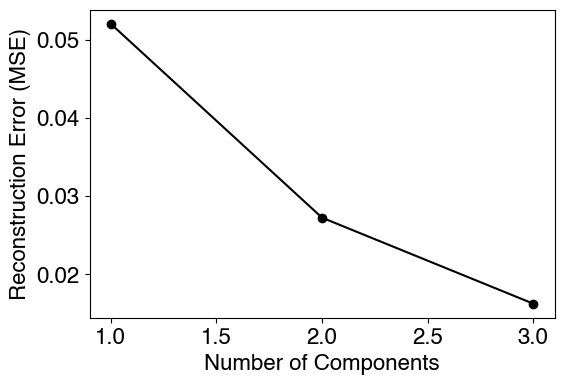

In [25]:
plt.figure(figsize=(6, 4))
plt.plot(reconstruction_errors_PCA_fin[:, 0]+1, reconstruction_errors_PCA_fin[:, 1], marker="o", linestyle="-", color="k")
plt.xlabel("Number of Components")
plt.ylabel("Reconstruction Error (MSE)")
plt.savefig(f"{output_dir}/Reconstruction_Error_vs_nComp3.png", dpi=600, bbox_inches="tight")
plt.show()

In [23]:
# 1. save PCs 
output_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/n_PC3'
pc_df = pd.DataFrame(pca_results, columns=[f'PC{i+1}' for i in range(3)])
pc_df['Defect_Type'] = data['Defect_Type']
pc_df['structures'] = structures
pc_df["carrier_type"] = data["carrier_type"]
pc_df.to_csv(f"{output_dir}/PCA_with_Defect_Types_v2.csv", index=False)

In [ ]:
import seaborn as sns

In [ ]:
#sns.set_theme(rc={'axes.facecolor': '#F2F2F7'})
#sns.reset_orig()
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 16
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False

output_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/plots/class_types/nPC3'
os.makedirs(output_dir, exist_ok=True)
# radial ranges
ranges = [(2.5, 4), (4, 7), (7, 10)]

# PC combinations
pc_combinations = [(0,1,2)]    

# Color map for PCs
pc_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink']

# Width of each bar
bar_width = 0.025

for combo in pc_combinations:
    for (low, high) in ranges:
        # Get indices of features in this range
        indices = [i for i, r in enumerate(radii_values) if low <= r < high]
        if not indices:
            continue

        selected_radii = [radii_values[i] for i in indices]

        plt.figure(figsize=(10, 3))
        for idx, pc_idx in enumerate(combo):
            pc_loadings = loadings[indices, pc_idx]
            plt.bar(
                selected_radii,
                pc_loadings,
                width=bar_width,
                alpha=0.5,
                color=pc_colors[pc_idx % len(pc_colors)],
                zorder=3,
                label=f'PC{pc_idx + 1}'
            )

        plt.xlabel("Radii (Å)", fontsize=16)
        plt.ylabel("PC Loadings", fontsize=16)
        #plt.title(f"{' vs '.join([f'PC{i+1}' for i in combo])} Loadings | Range: {low}-{high} Å")
        plt.xticks(ticks=np.arange(low, high + 0.5, 0.5), rotation=0)
        plt.ylim(-0.5, 0.5)
        plt.minorticks_on()
        plt.tick_params(which='both', direction='in', top=True, right=True, left=True, bottom = True)
        plt.tick_params(which='major', length=6)
        plt.tick_params(which='minor', length=3)
        plt.grid(True, alpha=0.2, color='gray', linewidth=0.6) #axis='y',
        plt.legend(loc="upper right", fontsize=10) #loc="center left", bbox_to_anchor=(1.02, 0.8), borderaxespad=0.0, 
        plt.tight_layout(rect=[0, 0, 0.82, 1])
        filename = f"{output_dir}/{'_vs_'.join([f'PC{i+1}' for i in combo])}_Range_{low}-{high}_hist_i_type.png"
        plt.savefig(filename, dpi=600, bbox_inches="tight")
        plt.show()

In [26]:
df = pd.read_csv("/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/n_PC3/PCA_Loadings_by_Radius_nPC3.csv")

In [27]:
# radius regimes
bins = [2.95, 4, 7, 10]
labels = ["2.5-4 Å", "4-7 Å", "7-10 Å"]
df["Regime"] = pd.cut(df["Radius (Å)"], bins=bins, labels=labels, include_lowest=True)

# long format
df_long = df.melt(id_vars=["Radius (Å)", "Regime"], var_name="PC", value_name="Loading")
df_long["Abs_Loading"] = df_long["Loading"].abs()

#### Top radial bins

In [28]:
selected_pc = "PC1"   
n = 10
# ------------------------------------

subset = df_long[df_long["PC"] == selected_pc]

for regime in labels:
    regime_subset = subset[subset["Regime"] == regime]
    print(f"\n{'='*55}")
    print(f"Regime: {regime}  |  {selected_pc}")
    print(f"{'='*55}")

    print(f"\n  Lowest {n} absolute loadings:")
    print(regime_subset.nsmallest(n, "Abs_Loading")[["Radius (Å)", "Loading", "Abs_Loading"]].to_string(index=False))

    print(f"\n  Highest {n} absolute loadings:")
    print(regime_subset.nlargest(n, "Abs_Loading")[["Radius (Å)", "Loading", "Abs_Loading"]].to_string(index=False))



Regime: 2.5-4 Å  |  PC1

  Lowest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       3.50 -0.015656     0.015656
       3.45 -0.020014     0.020014
       3.55 -0.026645     0.026645
       3.40 -0.034418     0.034418
       3.95 -0.036102     0.036102
       3.90 -0.036747     0.036747
       4.00 -0.042549     0.042549
       3.85 -0.045729     0.045729
       3.60 -0.048090     0.048090
       3.35 -0.056776     0.056776

  Highest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       3.10 -0.107943     0.107943
       3.05 -0.105868     0.105868
       3.00 -0.105554     0.105554
       3.15 -0.102492     0.102492
       2.95 -0.099339     0.099339
       3.20 -0.085520     0.085520
       3.30 -0.084527     0.084527
       3.25 -0.082121     0.082121
       3.70 -0.078090     0.078090
       3.65 -0.073580     0.073580

Regime: 4-7 Å  |  PC1

  Lowest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       4.85 -0.014849     0.014849
       4.90 -0.

In [29]:
selected_pc = "PC2"   
n = 10
# ------------------------------------

subset = df_long[df_long["PC"] == selected_pc]

for regime in labels:
    regime_subset = subset[subset["Regime"] == regime]
    print(f"\n{'='*55}")
    print(f"Regime: {regime}  |  {selected_pc}")
    print(f"{'='*55}")

    print(f"\n  Lowest {n} absolute loadings:")
    print(regime_subset.nsmallest(n, "Abs_Loading")[["Radius (Å)", "Loading", "Abs_Loading"]].to_string(index=False))

    print(f"\n  Highest {n} absolute loadings:")
    print(regime_subset.nlargest(n, "Abs_Loading")[["Radius (Å)", "Loading", "Abs_Loading"]].to_string(index=False))


Regime: 2.5-4 Å  |  PC2

  Lowest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       3.65 -0.001502     0.001502
       3.45  0.019430     0.019430
       3.00 -0.024254     0.024254
       3.35  0.033681     0.033681
       3.50 -0.035564     0.035564
       3.40  0.054902     0.054902
       3.30 -0.055010     0.055010
       2.95  0.057180     0.057180
       3.60 -0.074909     0.074909
       3.05 -0.083853     0.083853

  Highest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       3.80  0.136712     0.136712
       3.75  0.130322     0.130322
       4.00  0.111254     0.111254
       3.85  0.107077     0.107077
       3.25 -0.099535     0.099535
       3.20 -0.098253     0.098253
       3.95  0.094060     0.094060
       3.70  0.093286     0.093286
       3.55 -0.091915     0.091915
       3.10 -0.089151     0.089151

Regime: 4-7 Å  |  PC2

  Lowest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       5.75 -0.003510     0.003510
       6.35  0.

In [30]:
selected_pc = "PC3"   
n = 10
# ------------------------------------

subset = df_long[df_long["PC"] == selected_pc]

for regime in labels:
    regime_subset = subset[subset["Regime"] == regime]
    print(f"\n{'='*55}")
    print(f"Regime: {regime}  |  {selected_pc}")
    print(f"{'='*55}")

    print(f"\n  Lowest {n} absolute loadings:")
    print(regime_subset.nsmallest(n, "Abs_Loading")[["Radius (Å)", "Loading", "Abs_Loading"]].to_string(index=False))

    print(f"\n  Highest {n} absolute loadings:")
    print(regime_subset.nlargest(n, "Abs_Loading")[["Radius (Å)", "Loading", "Abs_Loading"]].to_string(index=False))


Regime: 2.5-4 Å  |  PC3

  Lowest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       3.10 -0.016811     0.016811
       3.85  0.018061     0.018061
       4.00  0.018826     0.018826
       3.80 -0.020111     0.020111
       3.95  0.020335     0.020335
       3.90  0.021520     0.021520
       3.15 -0.032892     0.032892
       2.95 -0.039720     0.039720
       3.25 -0.040164     0.040164
       3.05 -0.050202     0.050202

  Highest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       3.40  0.205562     0.205562
       3.70 -0.196364     0.196364
       3.65 -0.194892     0.194892
       3.45  0.194145     0.194145
       3.35  0.172113     0.172113
       3.50  0.167967     0.167967
       3.75 -0.096128     0.096128
       3.55  0.092516     0.092516
       3.00 -0.068258     0.068258
       3.60 -0.065638     0.065638

Regime: 4-7 Å  |  PC3

  Lowest 10 absolute loadings:
 Radius (Å)   Loading  Abs_Loading
       4.10 -0.000185     0.000185
       4.15 -0.